# Cone de previsão do ARIMA no WIN

Exemplo ilustrativo, **fora do protocolo de comparação** (não usa a grade, a validação nem a simulação do `tt1_comum`).
Mostra o que o ARIMA entrega quando se olha **vários candles à frente**: a previsão do caminho do preço e uma
banda de incerteza que **se abre com o horizonte**.

**Por que a banda se abre.** O modelo é ajustado no log-preço com uma diferença (d = 1), o que equivale a modelar o retorno.
O preço daqui a *h* candles é o preço atual mais a **soma** de *h* retornos futuros. Cada retorno traz um choque
imprevisível de variância σ², então as variâncias se somam: σ²·h. Assim, a meia-largura da banda cresce como **z·σ·√h**
(ajustada pelos termos AR/MA, quando existem).

**O que o gráfico mostra:**

| Elemento | Como é calculado |
|---|---|
| Ordem do modelo | ARIMA(p, 1, q), p e q de 0 a 2, com ou sem deriva, escolhido pelo **AIC** numa janela anterior à avaliada |
| Banda cinza ao longo dos candles | Banda de 80% de **1 passo** à frente, fora da amostra (parâmetros estimados antes desse trecho) |
| Cones cinza no passado | Previsão de *h* passos feita em datas passadas, para comparar com o que de fato aconteceu |
| Cone laranja | Previsão a partir do último candle: média (tracejado) e bandas de 80% e 95% |
| Painel | Modelo, coeficientes, σ por candle, previsão, banda de 80% no horizonte, RMSE contra "sem mudança", cobertura das bandas de 1 passo e teste de Ljung-Box nos resíduos |

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
warnings.filterwarnings("ignore")

_cands = [Path.cwd(), *Path.cwd().parents, Path("/content/data_science_no_mercado_financeiro")]
PASTA = str(next(p for p in _cands if (p / "tt1_comum.py").exists()))
sys.path.append(PASTA)
import tt1_comum as t
win = t.carregar(f"{PASTA}/dados/WINN_M1/WIN$N_M1.csv")
SAIDA = f"{PASTA}/resultados/estatistico"

AZUL, LARANJA, CINZA, TINTA, TINTA2 = "#2a78d6", "#eb6834", "#8a8984", "#0b0b0b", "#52514e"
ALTA, BAIXA, GRADE = "#1baf7a", "#e34948", "#e6e5e0"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": CINZA,
                     "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
                     "axes.titlecolor": TINTA, "font.size": 10})
print("WIN de", win.index.min(), "a", win.index.max())

WIN de 2020-10-15 11:49:00 a 2026-09-25 18:24:00


## Funções

- `escolher_ordem`: busca por AIC.
- `cone`: estima o modelo, avalia as bandas de 1 passo fora da amostra, gera cones passados e o cone futuro, e devolve o diagnóstico.
- `desenhar`: monta o gráfico.

A série modelada é `y = 100·ln(fechamento)`, então diferenças de `y` são exatamente o log-retorno em % usado no projeto.

In [2]:
def escolher_ordem(y):
    melhor = None
    for p in range(3):
        for q in range(3):
            for tr in ["n", "t"]:                        # "t" com d = 1 = deriva (retorno médio ≠ 0)
                try:
                    r = ARIMA(y, order=(p, 1, q), trend=tr).fit()
                except Exception:
                    continue
                if melhor is None or r.aic < melhor[0].aic:
                    melhor = (r, (p, 1, q), tr)
    return melhor[1], melhor[2]

def cone(ohlc, h, n_fit, n_aval, origens_passadas):
    '''ohlc: candles; h: horizonte do cone; n_fit: tamanho da janela de estimação;
    n_aval: últimos candles usados para avaliar as bandas de 1 passo fora da amostra;
    origens_passadas: posições (negativas, a partir do fim) de onde sair cada cone passado.'''
    y = 100 * np.log(ohlc.close.values)
    n = len(y)
    # 1) ordem e parâmetros estimados ANTES do trecho de avaliação
    y_tr = y[n - n_aval - n_fit: n - n_aval]
    ordem, tendencia = escolher_ordem(y_tr)
    r_tr = ARIMA(y_tr, order=ordem, trend=tendencia).fit()
    # 2) bandas de 1 passo fora da amostra: parâmetros fixos, filtro roda sobre treino + avaliação
    y_ap = y[n - n_aval - n_fit:]
    r_ap = r_tr.apply(y_ap)
    pr = r_ap.get_prediction(start=n_fit, end=len(y_ap) - 1)
    m1, c80, c95 = pr.predicted_mean, pr.conf_int(alpha=0.20), pr.conf_int(alpha=0.05)
    real, ant = y_ap[n_fit:], y_ap[n_fit - 1:-1]
    aval = dict(rmse_ratio=np.sqrt(np.mean((real - m1) ** 2)) / np.sqrt(np.mean((real - ant) ** 2)),
                cob80=np.mean((real >= c80[:, 0]) & (real <= c80[:, 1])),
                cob95=np.mean((real >= c95[:, 0]) & (real <= c95[:, 1])), n_aval=n_aval)
    banda1 = pd.DataFrame({"lo": np.exp(c80[:, 0] / 100), "hi": np.exp(c80[:, 1] / 100)}, index=ohlc.index[-n_aval:])
    # 3) cones passados: mesmos parâmetros, dados até a origem
    passados = []
    for o in origens_passadas:
        k = len(y_ap) + o                                   # o < 0
        f = r_tr.apply(y_ap[:k]).get_forecast(h)
        ci = f.conf_int(alpha=0.20)
        passados.append(dict(origem=n + o - 1, media=np.exp(f.predicted_mean / 100),
                             lo=np.exp(ci[:, 0] / 100), hi=np.exp(ci[:, 1] / 100)))
    # 4) modelo final: mesma ordem, re-estimado com os últimos n_fit candles; cone a partir do último
    r_f = ARIMA(y[-n_fit:], order=ordem, trend=tendencia).fit()
    f = r_f.get_forecast(h)
    ci80, ci95 = f.conf_int(alpha=0.20), f.conf_int(alpha=0.05)
    futuro = dict(media=np.exp(f.predicted_mean / 100), lo80=np.exp(ci80[:, 0] / 100), hi80=np.exp(ci80[:, 1] / 100),
                  lo95=np.exp(ci95[:, 0] / 100), hi95=np.exp(ci95[:, 1] / 100))
    lb = acorr_ljungbox(r_f.resid[1:], lags=[10], return_df=True)["lb_pvalue"].iloc[0]
    diag = dict(ordem=ordem, tendencia=tendencia, params=dict(zip(r_f.model.param_names, r_f.params)),
                sigma=np.sqrt(r_f.params[-1]), ljung_box_p=lb, ultimo=ohlc.close.iloc[-1], **aval)
    return futuro, passados, banda1, diag

def painel(diag, futuro, h, unidade, plural):
    p, d, q = diag["ordem"]
    nome = f"ARIMA({p},{d},{q})" + (" + deriva" if diag["tendencia"] == "t" else "") + ", AIC"
    coefs = ", ".join(f"{k.replace('.L', '')} {v:+.3f}" for k, v in diag["params"].items() if k != "sigma2") or "nenhum (passeio aleatório)"
    var = futuro["media"][-1] / diag["ultimo"] - 1
    prev = (f"{var:+.2%} em {h} {plural}" if abs(var) >= 5e-5
            else f"0,00% em {h} {plural} (= último preço)")
    return [("Modelo", nome), ("Coeficientes", coefs), (f"σ por {unidade}", f"{diag['sigma']:.2f}%"),
            ("Previsão", prev),
            ("Banda 80%", f"{futuro['lo80'][-1]:,.0f} a {futuro['hi80'][-1]:,.0f}".replace(",", ".")),
            ("RMSE / sem mudança", f"{diag['rmse_ratio']:.3f}" + (" (sem vantagem)" if diag["rmse_ratio"] >= 0.995 else "")),
            ("Cobertura 80% / 95%", f"{diag['cob80']:.0%} / {diag['cob95']:.0%} (n {diag['n_aval']})"),
            ("Resíduos", f"Ljung-Box p = {diag['ljung_box_p']:.3f}" + (" (ruído branco)" if diag["ljung_box_p"] > 0.05 else " (há estrutura)"))]

def desenhar(ohlc, n_show, h, futuro, passados, banda1, diag, unidade, plural, fmt_data, titulo, arquivo):
    v = ohlc.iloc[-n_show:]
    x = np.arange(n_show); xf = np.arange(n_show - 1, n_show + h)            # cone sai do último fechamento
    fig, (ax, axp) = plt.subplots(1, 2, figsize=(13, 5.6), gridspec_kw=dict(width_ratios=[3.3, 1], wspace=0.04))
    # banda de 1 passo (fora da amostra)
    b = banda1.reindex(v.index)
    ax.fill_between(x, b.lo.values, b.hi.values,
                    color=CINZA, alpha=0.18, lw=0, step="mid", label="banda de 80% de 1 passo (fora da amostra)")
    # cones passados
    for i, c in enumerate(passados):
        o = c["origem"] - (len(ohlc) - n_show)
        xc = np.arange(o, o + h + 1)
        base = ohlc.close.iloc[c["origem"]]
        ax.fill_between(xc, np.r_[base, c["lo"]], np.r_[base, c["hi"]], color=CINZA, alpha=0.22, lw=0,
                        label="cones de 80% feitos no passado" if i == 0 else None)
        ax.plot(xc, np.r_[base, c["media"]], color=CINZA, lw=1, ls="--")
    # candles
    sobe = v.close >= v.open
    cor = np.where(sobe, ALTA, BAIXA)
    ax.vlines(x, v.low, v.high, color=cor, lw=0.8)
    ax.bar(x, (v.close - v.open).abs().clip(lower=v.close.median() * 2e-5), bottom=np.minimum(v.open, v.close),
           width=0.65, color=cor, lw=0)
    # cone futuro
    u = v.close.iloc[-1]
    ax.fill_between(xf, np.r_[u, futuro["lo95"]], np.r_[u, futuro["hi95"]], color=LARANJA, alpha=0.12, lw=0, label="cone de 95%")
    ax.fill_between(xf, np.r_[u, futuro["lo80"]], np.r_[u, futuro["hi80"]], color=LARANJA, alpha=0.28, lw=0, label="cone de 80%")
    ax.plot(xf, np.r_[u, futuro["media"]], color=LARANJA, lw=2, ls="--", label="previsão (média)")
    ax.axvline(n_show - 0.5, color=CINZA, lw=0.8, ls=":")
    ax.annotate(f"{u:,.0f}".replace(",", "."), (n_show - 1, u), xytext=(-6, 0), textcoords="offset points",
                ha="right", va="center", fontsize=8.5, color=TINTA, bbox=dict(boxstyle="round,pad=0.2", fc="white", ec=CINZA, lw=0.6))
    for lab, yv in [("80%", futuro["hi80"][-1]), ("80%", futuro["lo80"][-1])]:
        ax.annotate(f"{yv:,.0f}".replace(",", "."), (n_show + h - 1, yv), xytext=(4, 0), textcoords="offset points",
                    va="center", fontsize=8.5, color=TINTA2)
    # eixo x: datas nos inícios de período
    rot = pd.Series(v.index.strftime(fmt_data))
    ini = rot.ne(rot.shift()).to_numpy().nonzero()[0]
    passo = max(1, len(ini) // 8)
    ax.set_xticks(ini[::passo], rot.iloc[ini[::passo]])
    ax.set_xlim(-1, n_show + h + max(6, int(0.09 * (n_show + h))))
    ax.set_ylabel("pontos (WIN)")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda val, _: f"{val:,.0f}".replace(",", ".")))
    ax.grid(axis="y", color=GRADE, lw=0.8); ax.set_axisbelow(True)
    ax.set_title(titulo, loc="left", fontsize=11)
    ax.legend(frameon=False, loc="lower left", fontsize=8.5, ncol=2)
    # painel de diagnóstico
    linhas = painel(diag, futuro, h, unidade, plural)
    axp.axis("off")
    axp.text(0.10, 1.0, "Diagnóstico do modelo", fontsize=10, color=TINTA, weight="bold", va="top")
    for i, (k, val) in enumerate(linhas):
        yv = 0.92 - i * 0.112
        axp.text(0.10, yv, k, fontsize=8.5, color=TINTA2, va="top")
        axp.text(0.10, yv - 0.042, val, fontsize=9, color=TINTA, va="top", wrap=True)
    fig.subplots_adjust(left=0.07, right=0.99, top=0.92, bottom=0.08)
    fig.savefig(arquivo, dpi=150); plt.show()
    return pd.DataFrame(linhas, columns=["item", "valor"])

## Candle diário (como no exemplo)

Janela de estimação de 500 pregões (~2 anos), cone de 20 pregões (~1 mês), bandas de 1 passo avaliadas nos últimos 250 pregões.

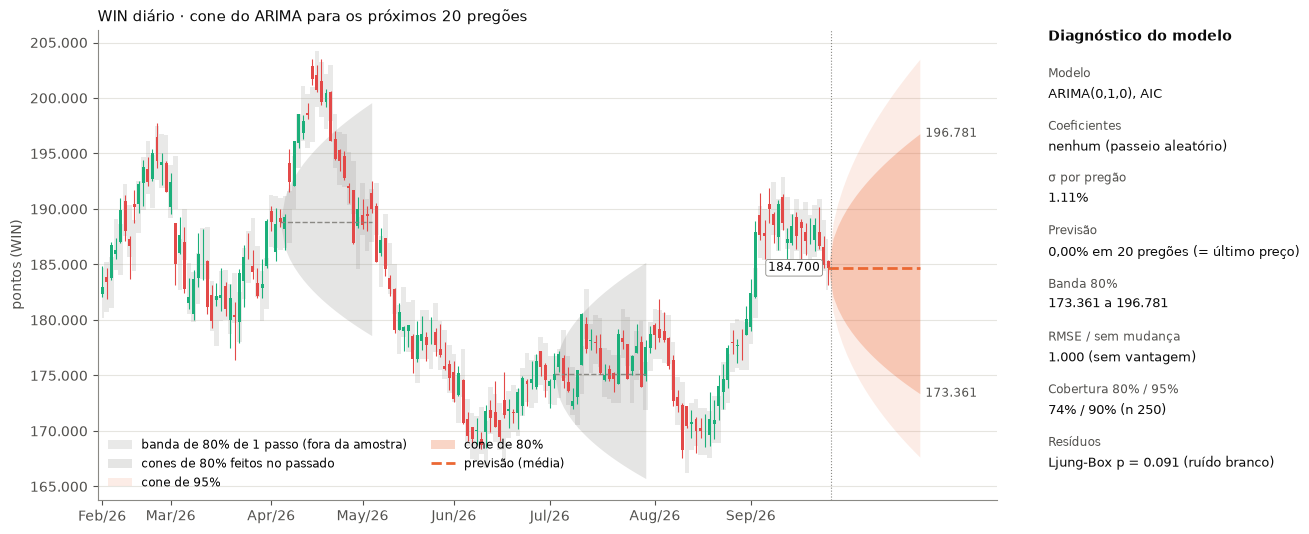

,item,valor
0,Modelo,"ARIMA(0,1,0), AIC"
1,Coeficientes,nenhum (passeio aleatório)
2,σ por pregão,1.11%
3,Previsão,"0,00% em 20 pregões (= último preço)"
4,Banda 80%,173.361 a 196.781
5,RMSE / sem mudança,1.000 (sem vantagem)
6,Cobertura 80% / 95%,74% / 90% (n 250)
7,Resíduos,Ljung-Box p = 0.091 (ruído branco)


In [3]:
dia = t.reamostrar(win, "1D")
H_D = 20
fut_d, pas_d, b1_d, diag_d = cone(dia, h=H_D, n_fit=500, n_aval=250, origens_passadas=[-120, -60])
desenhar(dia, n_show=160, h=H_D, futuro=fut_d, passados=pas_d, banda1=b1_d, diag=diag_d, unidade="pregão", plural="pregões",
         fmt_data="%b/%y", titulo=f"WIN diário · cone do ARIMA para os próximos {H_D} pregões",
         arquivo=f"{SAIDA}/cone_arima_diario.png")

## Candle de 60 min (o da frente estatística)

Janela de ~6 meses (1.250 candles), cone de 20 candles (~2 pregões), bandas de 1 passo avaliadas nos últimos 500 candles.

Atenção: aqui o modelo trata a série como contínua e **não sabe que existe a noite**. O cone que atravessa a virada do dia
não inclui o risco extra do gap de abertura, nem o fato de a abertura ser mais volátil (Etapa G do notebook principal).

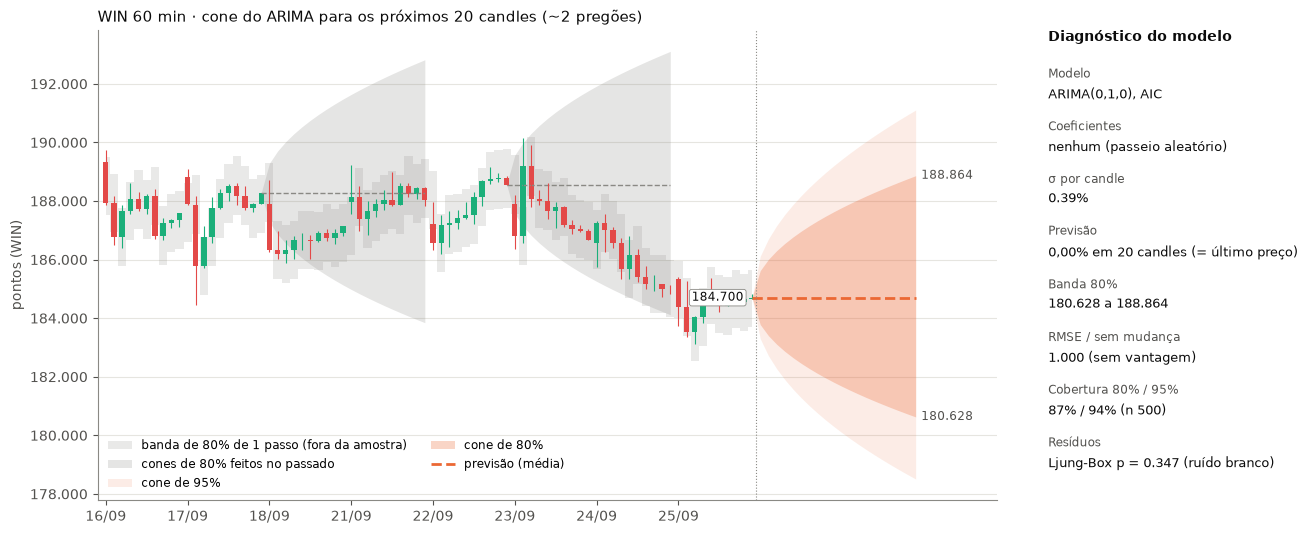

,item,valor
0,Modelo,"ARIMA(0,1,0), AIC"
1,Coeficientes,nenhum (passeio aleatório)
2,σ por candle,0.39%
3,Previsão,"0,00% em 20 candles (= último preço)"
4,Banda 80%,180.628 a 188.864
5,RMSE / sem mudança,1.000 (sem vantagem)
6,Cobertura 80% / 95%,87% / 94% (n 500)
7,Resíduos,Ljung-Box p = 0.347 (ruído branco)


In [4]:
h60 = t.reamostrar(win, "60min")
H_60 = 20
fut_h, pas_h, b1_h, diag_h = cone(h60, h=H_60, n_fit=1250, n_aval=500, origens_passadas=[-60, -30])
desenhar(h60, n_show=80, h=H_60, futuro=fut_h, passados=pas_h, banda1=b1_h, diag=diag_h, unidade="candle", plural="candles",
         fmt_data="%d/%m", titulo=f"WIN 60 min · cone do ARIMA para os próximos {H_60} candles (~2 pregões)",
         arquivo=f"{SAIDA}/cone_arima_60min.png")

## Leitura

- **O AIC escolheu ARIMA(0,1,0) sem deriva nos dois casos: o passeio aleatório.** Entre 18 modelos candidatos, o melhor é "o próximo preço é o atual mais um choque imprevisível". Prever retorno zero é exatamente o **naive** do projeto, então o ARIMA "ótimo" é o próprio naive (RMSE / sem mudança = 1,000). Isso bate com a grade da frente (Theil U ≈ 1 em tudo). O exemplo da LuxAlgo com o SPY chega ao mesmo lugar: ARIMA(0,1,0) e "no edge".
- **Por isso o centro do cone é uma linha reta no último preço.** O modelo não diz se o WIN vai subir ou descer. O que ele diz é **até onde pode ir**:
  - **diário:** σ = 1,11% por pregão. Em 20 pregões a banda de 80% vai de **173.361 a 196.781** (±6,3%, que é 1,28 · 1,11% · √20);
  - **60 min:** σ = 0,39% por candle. Em 20 candles (~2 pregões) a banda de 80% vai de **180.628 a 188.864** (±2,2%).
- **A abertura em √h.** Sem termos AR/MA, a variância do preço daqui a *h* passos é exatamente h·σ². É por isso que o cone tem forma de parábola deitada.
- **As bandas são boas, mas não perfeitas.** Na avaliação fora da amostra:
  - **diário:** a banda de 80% cobriu **74%** e a de 95% cobriu **90%**. As duas são estreitas demais, porque a volatilidade muda ao longo do tempo (meses calmos e meses turbulentos) e o modelo usa um σ fixo;
  - **60 min:** a banda de 80% cobriu **87%** (larga demais) e a de 95% cobriu **94%** (levemente estreita). Esse padrão é a assinatura de **caudas gordas**: a maioria dos candles é mais calma que a normal prevê, e alguns são muito mais violentos. Some-se a isso a volatilidade intradiária (Etapa G do notebook principal).
- **Os cones passados ajudam a calibrar a intuição.** Uma banda de 80% *deve* ser furada 1 em cada 5 vezes. No cone de abril (diário) o preço chegou a sair da banda; no de julho, ficou dentro.
- **Ljung-Box com p > 0,05 nos resíduos** (0,091 no diário, 0,347 em 60 min): não sobra autocorrelação para outro termo AR/MA explorar. É mais uma evidência de que o retorno é ruído do ponto de vista linear.
- **Limitação do cone em 60 min:** ele trata a série como contínua. A virada do dia (gap de abertura) e a abertura mais volátil não entram no cálculo, então o risco real de atravessar a noite é maior do que o cone mostra.

**Mensagem para a apresentação:** o ARIMA não prevê a direção (o centro do cone é plano), mas quantifica o risco: "com 80% de probabilidade, o WIN fica entre X e Y nos próximos *h* candles". Para que essa faixa fique calibrada, falta modelar a volatilidade que muda (GARCH, ou volatilidade por horário).